# Unicycle trajectory optimization with a discrete transition

A unicycle starts at the origin facing east and must reach $(3,2)$ m facing north after three seconds. Its body-frame speed and yaw rate produce a full next pose at each transition. State and control factors specify the objective on this chain. [C++ example](https://github.com/borglab/gtsam/blob/develop/gtsam_unstable/examples/mppi/UnicycleMPPITrajectoryOptimizationExample.cpp)

GTSAM Copyright 2010-2026, Georgia Tech Research Corporation,
Atlanta, Georgia 30332-0415

All Rights Reserved

Authors: Akash Ratheesh and Frank Dellaert (see THANKS for the full author list)

See LICENSE for the license information

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/borglab/gtsam/blob/develop/python/gtsam_unstable/examples/planning/UnicycleMPPITrajectoryOptimizationExample.ipynb)

In [1]:
try:
    import google.colab
    %pip install --quiet gtsam-develop plotly==6.3.1
except ImportError:
    pass

In [2]:
from html import escape
import numpy as np
import gtsam
import gtsam_unstable as unstable
from gtsam.symbol_shorthand import U, X
from plotly.subplots import make_subplots
from IPython.display import HTML, display

teal, orange = "#087B78", "#B65025"
plotly_js = "https://cdn.plot.ly/plotly-3.1.1.min.js"

## Encode the joint graph

Each dynamics factor connects a pose, its control, and the resulting pose. The same model predicts the next pose during a rollout, so this hard factor has zero error on every sampled trajectory. The pose and control priors then determine the graph score. A tighter terminal prior sets the cost of the final pose error.

In [3]:
H, dt = 30, 0.1
state_keys = [X(k) for k in range(H + 1)]
control_keys = [U(k) for k in range(H)]
model = unstable.Unicycle(dt)
start, goal = gtsam.Pose2(), gtsam.Pose2(3., 2., np.pi / 2)
running = gtsam.noiseModel.Diagonal.Precisions(np.array([1., 1., 0.1]))
terminal = gtsam.noiseModel.Diagonal.Precisions(np.array([100., 100., 10.]))
effort = gtsam.noiseModel.Isotropic.Precision(2, 0.1)
hard = gtsam.noiseModel.Constrained.All(3)

graph = gtsam.NonlinearFactorGraph()
for k, key in enumerate(control_keys):
    graph.add(unstable.UnicycleDynamicsFactor(state_keys[k], key, state_keys[k + 1], model, hard))
    graph.add(gtsam.PriorFactorVector(key, np.zeros(2), effort))
    graph.add(gtsam.PriorFactorPose2(state_keys[k + 1], goal, terminal if k == H - 1 else running))

## Roll out the discrete prediction

`Unicycle.predict` returns a complete next `Pose2` at the model's time step. The native `unicycleTransition(model)` adapter tells the planner to use that pose directly. A Gaussian proposal perturbs the 30 speed and yaw-rate commands, and MPPI forms a weighted mean after scoring all 1,024 candidates. Thirty updates produce an open-loop plan.

In [4]:
planner = gtsam.SamplingPlannerPose2Vector(state_keys, control_keys, dt)
proposal = gtsam.GaussianProposal(0.25 * np.eye(2), 1024, 42)
rule = gtsam.MPPI(1.0)
seed = gtsam.Values()
seed.insert(X(0), start)
zero_controls = np.zeros((2, H))
dynamics = unstable.unicycleTransition(model)
initial = planner.rollout(seed, zero_controls, dynamics)
plan = planner.optimize(graph, initial, dynamics, proposal, rule, 30)

## Read the pose and control sequence

Translation and orientation measure two parts of the terminal pose error. The rotation between the last pose and the goal gives an angular error that remains meaningful across angle wraparound.

In [5]:
poses = [plan.atPose2(key) for key in state_keys]
path = np.array([[p.x(), p.y(), p.theta()] for p in poses])
controls = planner.nominalControls(plan).T
time = dt * np.arange(H + 1)
distance = np.linalg.norm(poses[-1].translation() - goal.translation())
heading_error = abs(goal.rotation().between(poses[-1].rotation()).theta())
print(f"Graph error {graph.error(initial):.2f} → {graph.error(plan):.2f}")
print(f"Terminal distance {distance:.3f} m, heading error {heading_error:.3f} rad")

Graph error 854.41 → 23.27
Terminal distance 0.007 m, heading error 0.041 rad


Arrowheads mark the robot heading every half second. Read the speed and yaw-rate profiles together to see how the robot turns its body along the path and aligns with the terminal orientation. Interactive figures require an internet connection.

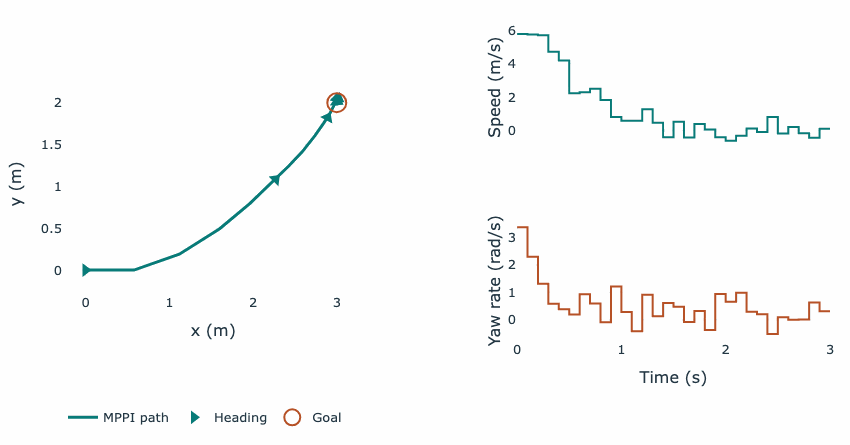

In [6]:
fig = make_subplots(rows=2, cols=2, specs=[[{"rowspan": 2}, {}], [None, {}]],
                    column_widths=[0.49, 0.51], horizontal_spacing=0.20, vertical_spacing=0.24)
fig.add_scatter(x=path[:, 0], y=path[:, 1], mode="lines", name="MPPI path",
                line=dict(color=teal, width=3), row=1, col=1)
fig.add_scatter(x=path[::5, 0], y=path[::5, 1], mode="markers", name="Heading",
                marker=dict(symbol="triangle-up", size=12, color=teal,
                            angle=90 - np.rad2deg(path[::5, 2])),
                customdata=np.c_[time[::5], np.rad2deg(path[::5, 2])],
                hovertemplate="%{customdata[0]:.1f} s · %{customdata[1]:.1f}°<extra></extra>",
                row=1, col=1)
fig.add_scatter(x=[goal.x()], y=[goal.y()], mode="markers", name="Goal",
                marker=dict(symbol="circle-open", size=19, color=orange, line_width=2), row=1, col=1)
for axis, label, color, row in [(0, "Speed (m/s)", teal, 1), (1, "Yaw rate (rad/s)", orange, 2)]:
    fig.add_scatter(x=time, y=np.r_[controls[:, axis], controls[-1, axis]], mode="lines",
                    line=dict(color=color, shape="hv"), name=label, showlegend=False, row=row, col=2)
    fig.update_yaxes(title_text=label, title_standoff=3, row=row, col=2)
fig.update_xaxes(title_text="x (m)", row=1, col=1)
fig.update_yaxes(title_text="y (m)", scaleanchor="x", scaleratio=1, constrain="domain", row=1, col=1)
fig.update_xaxes(matches="x3", showticklabels=False, row=1, col=2)
fig.update_xaxes(title_text="Time (s)", row=2, col=2)
fig.update_layout(template="plotly_white", height=445, margin=dict(l=63, r=20, t=28, b=65),
                  font=dict(size=13, color="#243744"), hoverlabel=dict(namelength=-1),
                  legend=dict(orientation="h", y=-0.20, x=0))
# Give Plotly its own document so the figure also runs in the published guide.
plot = fig.to_html(full_html=False, include_plotlyjs=plotly_js,
                   config={"displaylogo": False, "responsive": True})
document = '<!doctype html><meta charset="utf-8"><style>body{margin:0}</style>' + plot
display(HTML(f'<iframe title="Unicycle trajectory optimization with a discrete transition" style="width:100%;border:0" '
             f'height="{fig.layout.height}" srcdoc="{escape(document, quote=True)}"></iframe>'))